<a href="https://colab.research.google.com/github/cpython-projects/da_27_07_2026/blob/main/lesson_16_hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏡 Сервіс порівняння цін на будинки — частина 2

Команда продовжує працювати над тим самим сервісом. Попередня домашня робота дала перші орієнтири по типовій ціні та сегментах ринку. Тепер до команди приєднався data scientist, який хоче будувати на цих даних **статистичні та прогнозні моделі**, і ставить аналітикам кілька практичних питань.

**Датасет:** [House Sales in King County, USA (Kaggle)](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) (той самий, що й минулого разу).

> У кожному завданні нижче **не названо метод**, яким його слід розв'язувати. Ваша частина роботи — самостійно визначити, який інструмент із лекції про розподіли (гістограма, `skew`/`kurt`, QQ-plot, нормальність, log-трансформація, Z-score, IQR, Poisson-перевірка, сегментація) тут підходить і чому.

In [1]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/cpython-projects/python_da_17_03_26/refs/heads/main/kc_house_data.csv')
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530.0,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310.0,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020.0,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600.0,0,2004,0,98027,47.5345,-122.069,1410,1287


## **Завдання 1. Чи можна довіряти лінійній моделі "як є"?**

Data scientist хоче побудувати просту модель прогнозування ціни (`price`) і каже: *"Лінійні моделі найкраще працюють, коли цільова змінна приблизно нормально розподілена — давай просто перевіримо це на око по гістограмі і поїдемо далі."*

1. Чи достатньо "на око по гістограмі", щоб відповісти на таке питання? Яким чином можна перевірити це **формально**, а не лише візуально?
2. Якщо виявиться, що `price` далека від нормального розподілу — це проблема, яку не можна виправити, чи є стандартний прийом, який наближає такі дані до нормальної форми? Перевірте, чи він тут спрацює, і наскільки.
3. Що з цього випливає для фінальної моделі: з якою величиною їй варто працювати — з `price` чи з чимось іншим?

In [7]:
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
df.price.skew()

np.float64(4.024069144684712)

In [3]:
df.price.kurtosis()

np.float64(34.58554043194243)

In [6]:
stats.normaltest(df.price)

NormaltestResult(statistic=np.float64(19121.788941861127), pvalue=np.float64(0.0))

<Axes: >

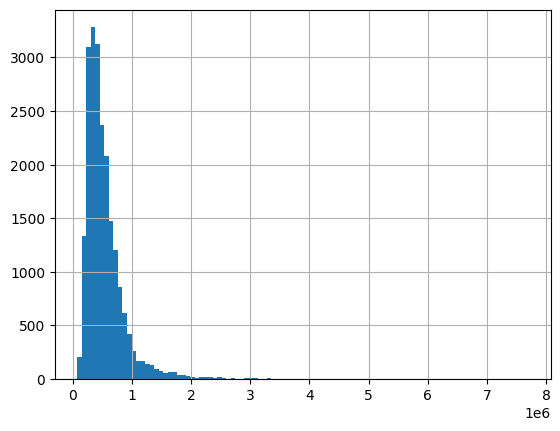

In [4]:
df.price.hist(bins=100)

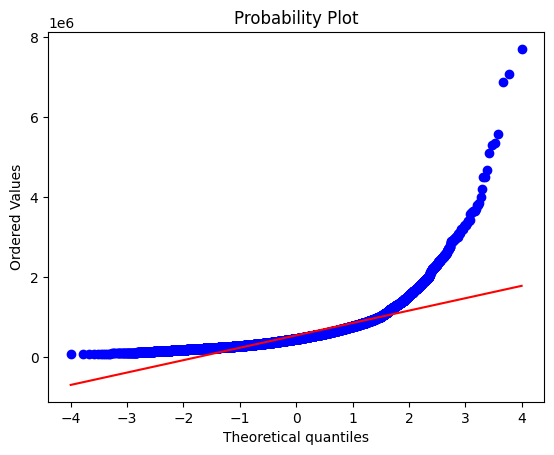

In [8]:
stats.probplot(df.price, dist='norm', plot=plt)
plt.show()

In [9]:
import numpy as np

log_price = np.log(df.price)

<Axes: >

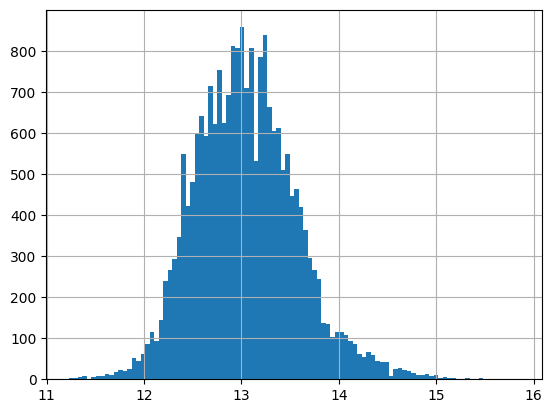

In [13]:
log_price.hist(bins=100)

In [14]:
log_price.skew()

np.float64(0.42807247557592526)

In [15]:
log_price.kurtosis()

np.float64(0.691853952835281)

## **Завдання 2. Підозрілі оголошення в базі**

Перед запуском сервісу команда хоче автоматично позначати оголошення, які виглядають як **помилка внесення даних**, а не як реальний унікальний будинок (наприклад, у `bedrooms`).

1. Запропонуйте спосіб автоматично знаходити такі "підозрілі" значення без ручного перегляду 21 613 рядків.
2. Перш ніж застосовувати метод — подивіться на форму розподілу `bedrooms`. Чи це той випадок, де обраний метод буде надійним? Обґрунтуйте, чи потрібно щось врахувати чи скоригувати, перш ніж його застосовувати.
3. Скільки оголошень ваш метод позначив як підозрілі? Переглянь їх вручну — чи це справді виглядає як помилки?

In [17]:
df.bedrooms.skew()

np.float64(1.97429953543601)

<Axes: >

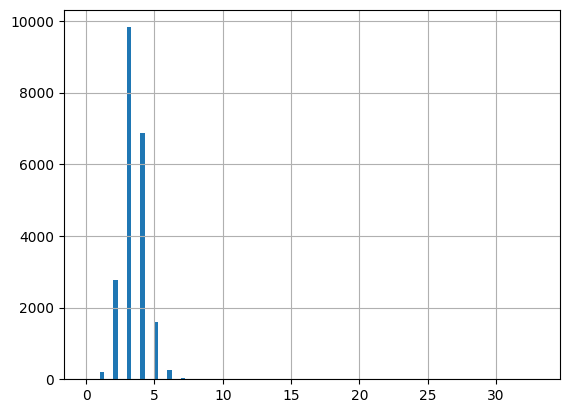

In [16]:
df.bedrooms.hist(bins=100)

In [20]:
q1, q3 = df.bedrooms.quantile(0.25), df.bedrooms.quantile(0.75)
IQR = q3 - q1
lower, upper = q1 - 1.5 * IQR, q3 + 1.5 * IQR
lower, upper

(np.float64(1.5), np.float64(5.5))

<Axes: >

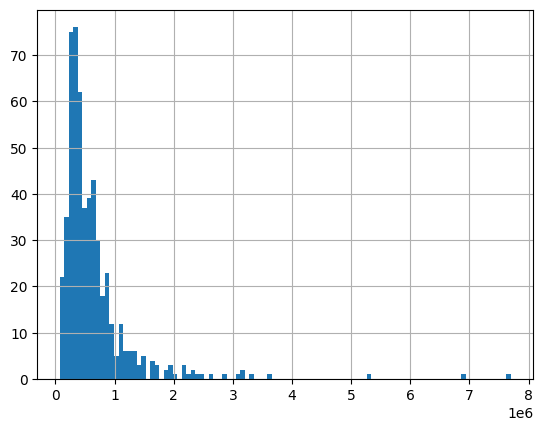

In [22]:
df_others = df[(df.bedrooms < lower) | (df.bedrooms > upper)]
df_others.price.hist(bins=100)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21611 non-null  float64
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [24]:
df.bedrooms.min()

0

In [25]:
df['sqft_per_room'] = df.sqft_living / df.bedrooms.replace(0, np.nan)

<Axes: >

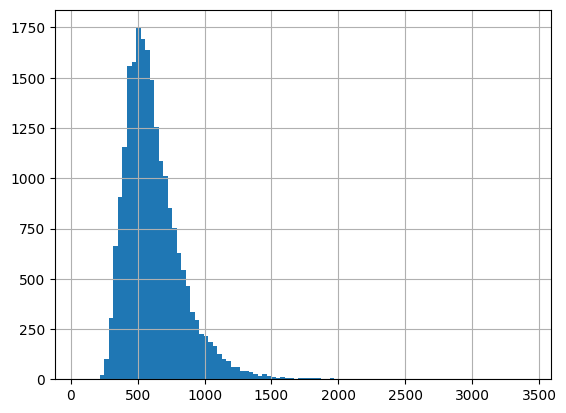

In [26]:
df.sqft_per_room.hist(bins=100)

In [29]:
df.sqft_per_room.min()

49.09090909090909

In [30]:
df[(df.sqft_per_room > 2000) | (df.sqft_per_room < 100)]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sqft_per_room
1653,2025079033,20141210T000000,415000.0,1,2.00,3000,204732,2.5,0,2,...,3000.0,0,1979,0,98014,47.6331,-121.945,2330,213008,3000.000000
2125,4379600030,20140729T000000,1325000.0,3,3.75,6400,76665,1.0,0,2,...,3810.0,2590,1966,0,98177,47.7313,-122.370,3430,60548,2133.333333
2444,7524900003,20141210T000000,3278000.0,2,1.75,6840,10000,2.5,1,4,...,4350.0,2490,2001,0,98008,47.6042,-122.112,3120,12300,3420.000000
3914,9808700762,20140611T000000,7062500.0,5,4.50,10040,37325,2.0,1,2,...,7680.0,2360,1940,2001,98004,47.6500,-122.214,3930,25449,2008.000000
5582,537000130,20140908T000000,360000.0,1,2.25,2060,10600,1.5,0,0,...,1560.0,500,1927,1983,98003,47.3291,-122.304,2060,11880,2060.000000
7252,6762700020,20141013T000000,7700000.0,6,8.00,12050,27600,2.5,0,3,...,8570.0,3480,1910,1987,98102,47.6298,-122.323,3940,8800,2008.333333
7725,3876313030,20140520T000000,458000.0,1,2.25,2140,10350,1.0,0,0,...,1470.0,670,1976,0,98072,47.7352,-122.170,1980,8400,2140.000000
13843,8122100355,20140924T000000,550000.0,1,1.00,2880,7560,1.0,0,0,...,1440.0,1440,1925,2014,98126,47.5370,-122.375,1400,5040,2880.000000
15567,5493110080,20140815T000000,1825000.0,3,3.75,6030,39317,2.0,0,0,...,4440.0,1590,1991,0,98004,47.6055,-122.210,4040,12333,2010.000000
15870,2402100895,20140625T000000,640000.0,33,1.75,1620,6000,1.0,0,0,...,1040.0,580,1947,0,98103,47.6878,-122.331,1330,4700,49.090909


## **Завдання 3. Один опис для всього ринку — чи для кожного сегменту окремо?**

У датасеті є будинки на набережній (`waterfront == 1`) і звичайні (`waterfront == 0`).

1. Команда хоче описати ціновий ринок одним середнім і одним стандартним відхиленням — "середня ціна будинку в регіоні становить X ± Y". Чи коректно рахувати ці X і Y по **всьому** датасету одразу, незалежно від `waterfront`?
2. Порівняйте форму розподілу ціни **в кожній із двох груп окремо**. Чим вони відрізняються?
3. Що станеться з виявленням аномальних (занадто дорогих/дешевих) об'єктів, якщо застосувати один і той самий метод і той самий поріг до об'єднаних даних, а не до кожної групи окремо? Проілюструйте конкретним прикладом будинку, з яким це станеться.

<Axes: >

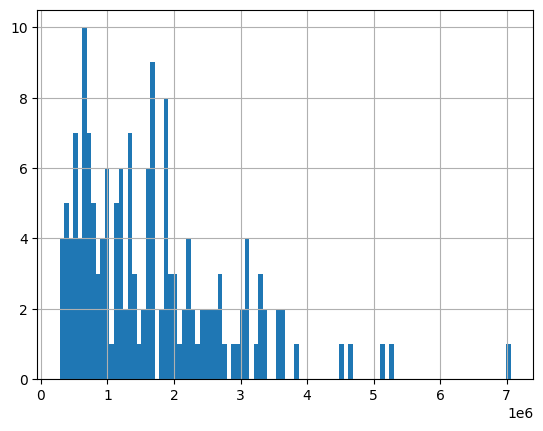

In [32]:
df_yes = df[df.waterfront == 1]
df_no = df[df.waterfront == 0]

df_yes.price.hist(bins=100)

<Axes: >

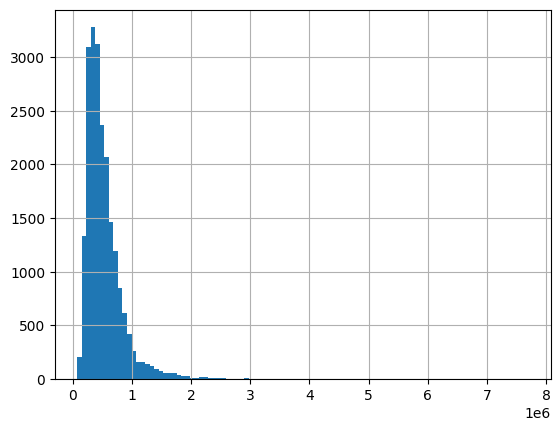

In [33]:
df_no.price.hist(bins=100)

In [34]:
len(df_yes), len(df_no)

(163, 21450)

In [35]:
df_yes.price.median(), df_no.price.median()

(1400000.0, 450000.0)

## **Завдання 4. Чи "кількість спалень" — це типовий підрахунок подій?**

У лекції розглядався розподіл Пуассона як модель для дискретних величин типу "скільки разів щось відбулося" (дзвінки, замовлення, дефекти). Комусь із команди спало на думку, що `bedrooms` — це теж ціле невід'ємне число, тож можна змоделювати його як Пуассонівську величину.

1. Яка ключова властивість розподілу Пуассона дозволяє перевірити, підходить він для даної величини чи ні (без побудови жодного графіка)?
2. Перевірте цю властивість на `bedrooms`. Що показує результат?
3. Сформулюйте висновок: чи достатньо того, що величина ціла й невід'ємна, щоб застосовувати до неї модель Пуассона? Який висновок для аналітика звідси випливає загалом — не лише для цього датасету?

In [37]:
mean = df.bedrooms.mean()
var = df.bedrooms.var()

var / mean

np.float64(0.25661692434027084)